# Homework 11


**Concepts covered:**

pandas `DataFrame`s: grouping data, querying `DataFrame`s, joining multiple `DataFrame`s, sampling.

**Instructions:**

Be sure to run each code block after you edit it to make sure it runs as expected. When you are done, we strongly recommend you run all the code from scratch (Runtime menu -> Restart and Run all) to make sure your current code works for all problems.

If your code raises an exception when run from scratch, it will interfere with the auto-grader process causing you to lose some or all points for this homework. Please ask for help on Piazza, attend office hours or schedule an appointment with your learning facilitator if you get stuck.

**Warning about AI:**

It is **strictly forbidden to use any generative AI (e.g., ChatGPT, Claude, Gemini, CoPilot or any similar tools**) to write solutions for any assignment. Students who submit work that is not authentically their own individual work will earn a grade of 0 on this assignment.


**Docstrings and Comments:**

Include a *documentation string* (docstring) for each function definition, as well as comments in the body of your code to explain each control structures (e.g., decision, loop), function call, or formula.

## Shared Imports

Do not install or use any additional modules.
Installing additional modules may result in an autograder failure resulting in zero points for some or all problems.

In [88]:
# shared imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.close("all")


**Note: This assignment is partially manually graded, so please allow some time for you to get your final scores.**

**Review Problem 1**

**Concept:** *`DataFrame`: initialization, line plots.*

**Task:**


Using the Starbucks stock dataset:

1. Load the `SBUX.csv` dataset into a DataFrame named `df_sbux`.
2. Convert the `date` column to a pandas datetime format and set it as the index.
3. Create a line plot showing both the `high` and `low` prices over time.

Your plot should include:

* both high and low columns plotted together
* a title
* a key


/tmp/ipykernel_2206/4081201904.py:7: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_sbux.set_index('date', inplace=True)


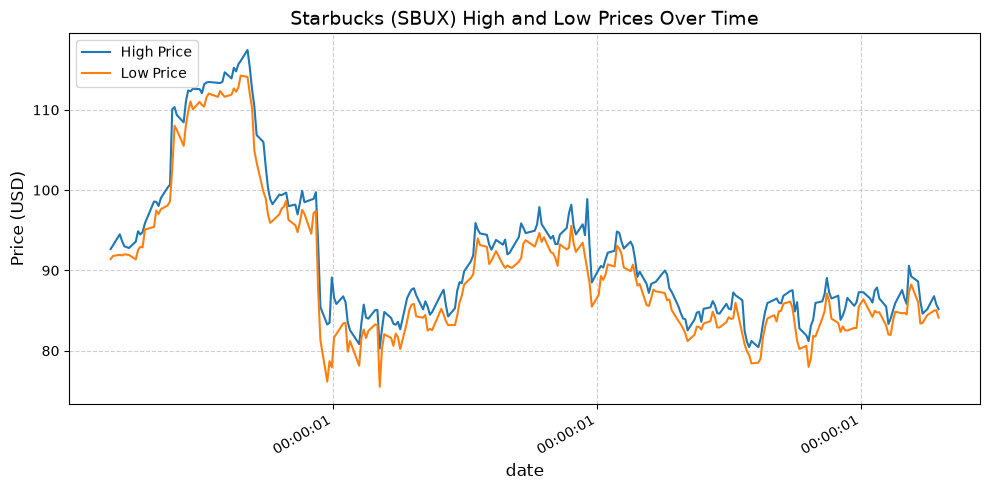

In [89]:
# Your Solution
''' load SBUX.csv dataset into a DataFrame named df_sbux '''
df_sbux = pd.read_csv('SBUX.csv')

''' Convert the date column to pandas datetime format and set it as the index'''
df_sbux['date'] = pd.to_datetime(df_sbux['date'])
df_sbux.set_index('date', inplace=True)

''' plot showing both high and low prices over time '''
df_sbux[['high', 'low']].plot(figsize=(10, 5), linewidth=1.5)

plt.title('Starbucks (SBUX) High and Low Prices Over Time', fontsize=14)
plt.xlabel('date', fontsize=12)
plt.ylabel('Price (USD)', fontsize=12)
plt.legend(['High Price', 'Low Price'], loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()



Review Problem 2

**Concept:** *`DataFrame`: initialization, descriptive statistics, histogram.*

**Task:**

Using the `SBUX.csv` dataset:

1. Load the dataset into a DataFrame named `df_sbux`.
2. Convert the `date` column to a pandas datetime format and set it as the index.
3. Compute the **daily return** of the stock using the `close` column (percentage change).
4. Display the **descriptive statistics** of the daily returns.
5. Create a **histogram** of the daily returns using 25 bins.
6. Identify **outliers** where the return falls outside of **mean ± 3 standard deviations**.
7. Print:
    *  the upper and lower bounds
    * the number of values above and below these bounds
    * the list of outlier values (sorted by date)


/tmp/ipykernel_2206/3343810475.py:7: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_sbux.set_index('date', inplace=True)


Descriptive Statistics of Daily Returns
count    249.000000
mean      -0.000130
std        0.021601
min       -0.112162
25%       -0.011336
50%        0.000107
75%        0.011323
max        0.112812
Name: Daily_Return, dtype: float64


=== Outlier Analysis (Mean ± 3 Standard Deviations) ===
Mean Return:        -0.000130
Standard Deviation: 0.021601
Upper Bound:        0.064672
Lower Bound:        -0.064932

Number of values above upper bound: 3
Number of values below lower bound: 2
Total outliers detected:            5

List of outlier values (sorted chronologically by date):
date
1970-01-01 00:00:01.738161000    0.081366
1970-01-01 00:00:01.743687000   -0.112162
1970-01-01 00:00:01.743773400   -0.069794
1970-01-01 00:00:01.744205400    0.112812
1970-01-01 00:00:01.747056600    0.066874
Name: Daily_Return, dtype: float64


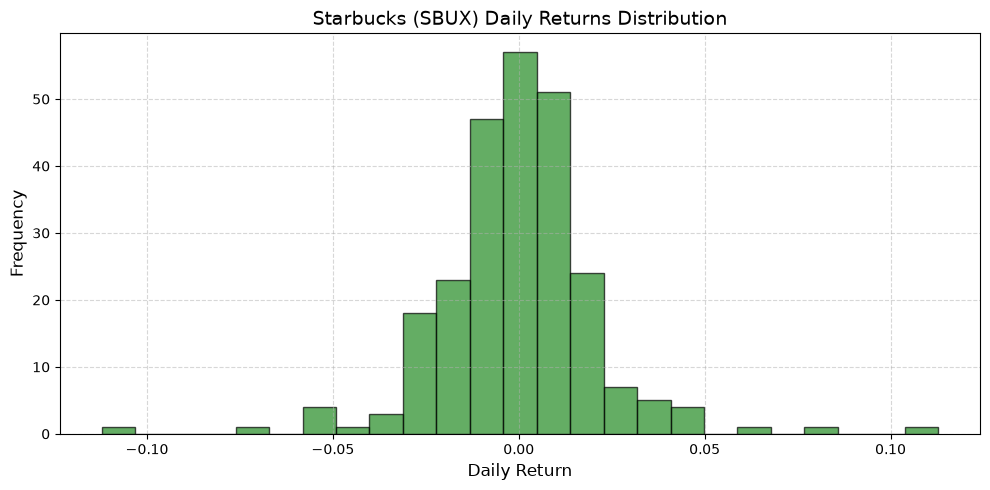

In [90]:
# Your Solution
'''Conver data, compute and display descriptive statistics'''
df_sbux = pd.read_csv('SBUX.csv')


df_sbux['date'] = pd.to_datetime(df_sbux['date'])
df_sbux.set_index('date', inplace=True)

df_sbux['Daily_Return'] = df_sbux['close'].pct_change()

'''The internet advises to drop the NaN values for clean statiscal values'''
daily_returns = df_sbux['Daily_Return'].dropna()

'''statiscal values'''
print('Descriptive Statistics of Daily Returns')
print(daily_returns.describe())
print('\n')


plt.figure(figsize=(10, 5))
plt.hist(daily_returns, bins=25, color='forestgreen', edgecolor='black', alpha=0.7)
plt.title('Starbucks (SBUX) Daily Returns Distribution', fontsize=14)
plt.xlabel('Daily Return', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

'''outliers'''
mean_return = daily_returns.mean()
std_return = daily_returns.std()

upper_bound = mean_return + (3 * std_return)
lower_bound = mean_return - (3 * std_return)

'''create the list of outliers'''
outliers = daily_returns[
    (daily_returns > upper_bound) | (daily_returns < lower_bound)]

above_count = (daily_returns > upper_bound).sum()
below_count = (daily_returns < lower_bound).sum()

print('=== Outlier Analysis (Mean ± 3 Standard Deviations) ===')
print(f'Mean Return:        {mean_return:.6f}')
print(f'Standard Deviation: {std_return:.6f}')
print(f'Upper Bound:        {upper_bound:.6f}')
print(f'Lower Bound:        {lower_bound:.6f}\n')

print(f'Number of values above upper bound: {above_count}')
print(f'Number of values below lower bound: {below_count}')
print(f'Total outliers detected:            {len(outliers)}\n')

print('List of outlier values (sorted chronologically by date):')
print(outliers.sort_index())



Test case for problem 2

In [91]:
# Test Case:



**Problem 3**

**Concept:** *Grouping Data, plotting*


**Task:**

Using the `02215_weather.csv` dataset:

1. Load the dataset into a DataFrame named `df_weather`.
2. Convert the `datetime` column to a pandas datetime format and set it as the index.
3. Use the icon column as a categorical variable and group the data by `icon`.
4. Create a **pie chart** showing the count of each weather icon category.

Your chart should include:
* labels for each category
* a title



/tmp/ipykernel_2206/1119955899.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_weather['datetime'] = pd.to_datetime(df_weather['datetime'])
/tmp/ipykernel_2206/1119955899.py:7: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_weather.set_index('datetime', inplace=True)


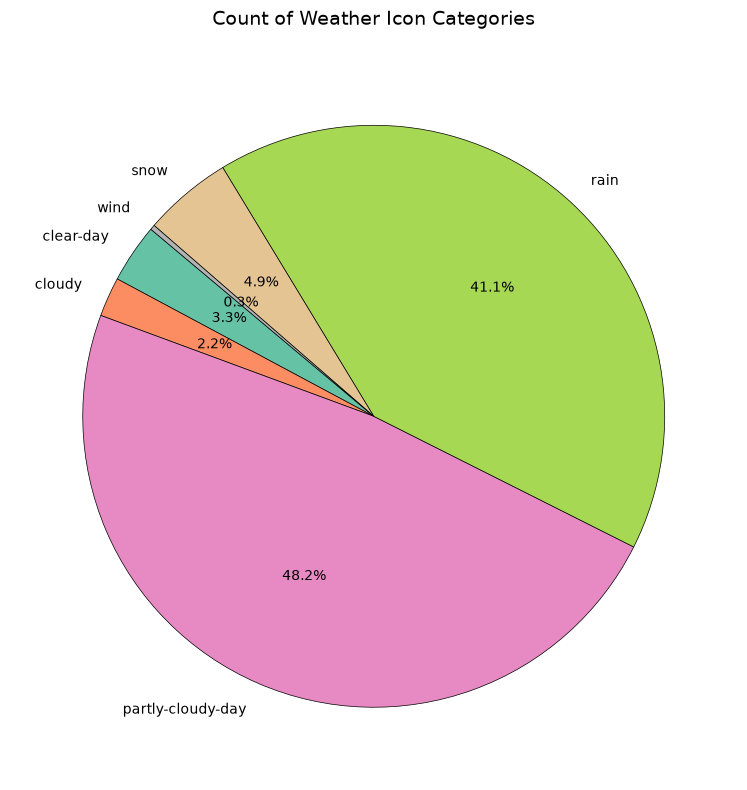

In [92]:
# Your Solution
'''Create pie chart with categorical data'''
df_weather = pd.read_csv('02215_weather.csv')

# Convert the datetime column to a pandas datetime format and set it as the index
df_weather['datetime'] = pd.to_datetime(df_weather['datetime'])
df_weather.set_index('datetime', inplace=True)

df_weather['icon'] = df_weather['icon'].astype('category')
icon_counts = df_weather.groupby('icon', observed=False).size()

plt.figure(figsize=(8, 8))
icon_counts.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=140,
    cmap='Set2',
    wedgeprops={'edgecolor': 'black', 'linewidth': 0.5},
)

plt.title('Count of Weather Icon Categories', fontsize=14, pad=20)
plt.ylabel('')  # Removes the default y-axis label for a cleaner look

plt.tight_layout()



**Problem 4**

**Concept:** *Grouping Data, plotting*


**Task:**

Using the `02215_weather.csv` dataset:

1. Use the existing grouped object based on the `icon` column from **Problem 3**.
2. Create a **histogram** of the `tempmax` column for each weather condition group.

Your plot should include:
* 25 bins
* transparency so overlapping distributions can be seen
* a legend
* a title


/tmp/ipykernel_2206/1938892156.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_weather['datetime'] = pd.to_datetime(df_weather['datetime'])
/tmp/ipykernel_2206/1938892156.py:5: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_weather.set_index('datetime', inplace=True)


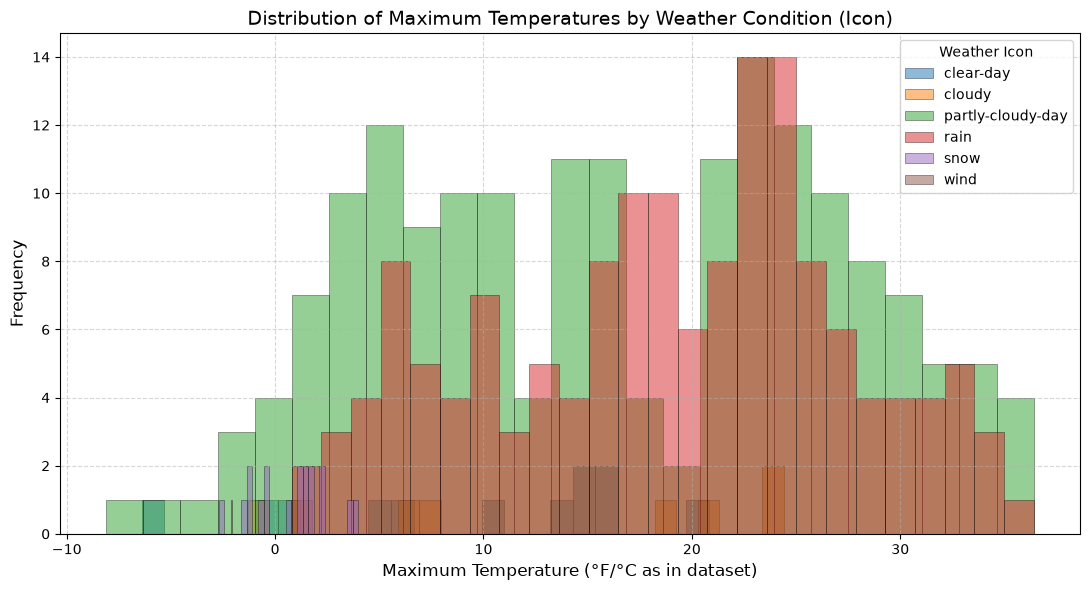

In [93]:
# Your Solution
'''create a histogra'''
df_weather = pd.read_csv('02215_weather.csv')
df_weather['datetime'] = pd.to_datetime(df_weather['datetime'])
df_weather.set_index('datetime', inplace=True)

df_weather['icon'] = df_weather['icon'].astype('category')
grouped_weather = df_weather.groupby('icon', observed=False)

plt.figure(figsize=(11, 6))

for name, group in grouped_weather:
  tempmax_data = group['tempmax'].dropna()
  if not tempmax_data.empty:
    plt.hist(
        tempmax_data,
        bins=25,
        alpha=0.5,  
        label=str(name),
        edgecolor='black',
        linewidth=0.5,
    )

plt.title(
    'Distribution of Maximum Temperatures by Weather Condition (Icon)',
    fontsize=14,
)
plt.xlabel('Maximum Temperature (°F/°C as in dataset)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.legend(title='Weather Icon', loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()



**Problem 5**

**Concept:** *Grouping Data, plotting*


**Task:**

Using the `02215_weather.csv` dataset:

1. Use the existing grouped object based on the `icon` column from **Problem 3**.
2. Create a histogram of the `precip` column for each weather condition group.

Your plot should include:

* 10 bins
* transparency so overlapping distributions can be seen
* a legend
* a title



/tmp/ipykernel_2206/639277407.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_weather['datetime'] = pd.to_datetime(df_weather['datetime'])
/tmp/ipykernel_2206/639277407.py:5: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_weather.set_index('datetime', inplace=True)


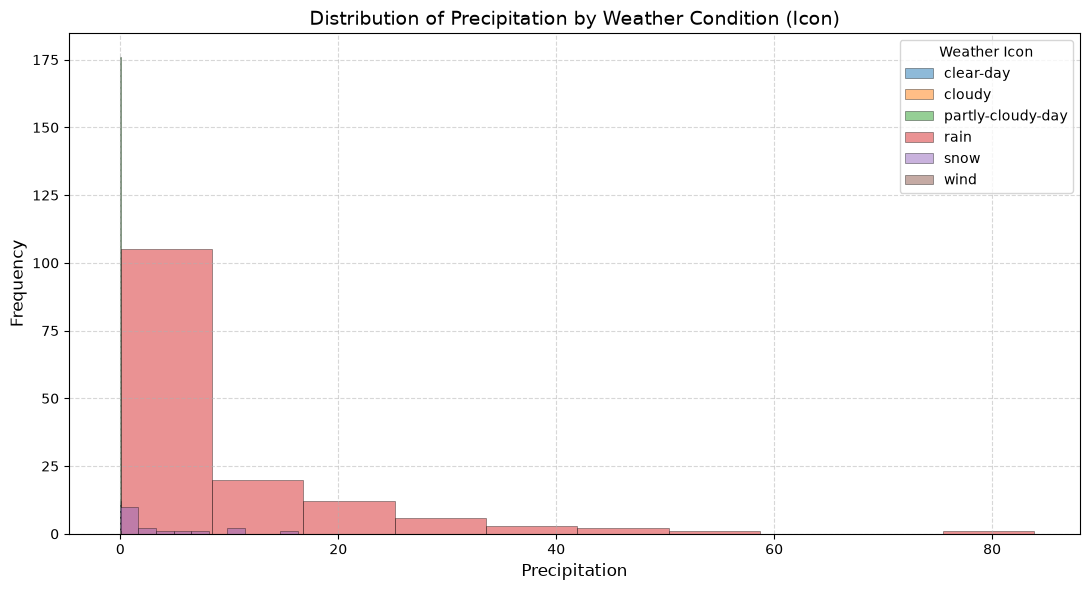

In [94]:
# Your Solution
'''Create histogram of precip'''
df_weather = pd.read_csv('02215_weather.csv')
df_weather['datetime'] = pd.to_datetime(df_weather['datetime'])
df_weather.set_index('datetime', inplace=True)

df_weather['icon'] = df_weather['icon'].astype('category')
grouped_weather = df_weather.groupby('icon', observed=False)

plt.figure(figsize=(11, 6))

for name, group in grouped_weather:
  precip_data = group['precip'].dropna()
  if not precip_data.empty:
    plt.hist(
        precip_data,
        bins=10,  
        alpha=0.5,  
        label=str(name),
        edgecolor='black',
        linewidth=0.5,
    )

plt.title(
    'Distribution of Precipitation by Weather Condition (Icon)', fontsize=14
)
plt.xlabel('Precipitation', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.legend(title='Weather Icon', loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()



**Problem 6**

**Concept:** *Grouping Data, plotting*


**Task:**


Using the `02215_weather.csv` dataset:

1. Use the existing grouped object based on the `icon` column from **Problem 3**.
2. Compute the **mean** of the `tempmax` column for each weather condition group.
3. Create a **bar chart** to display the mean maximum temperature for each group.


Your plot should include:

* one bar for each weather icon category
* a title



/tmp/ipykernel_2206/1966647199.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_weather['datetime'] = pd.to_datetime(df_weather['datetime'])
/tmp/ipykernel_2206/1966647199.py:5: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_weather.set_index('datetime', inplace=True)


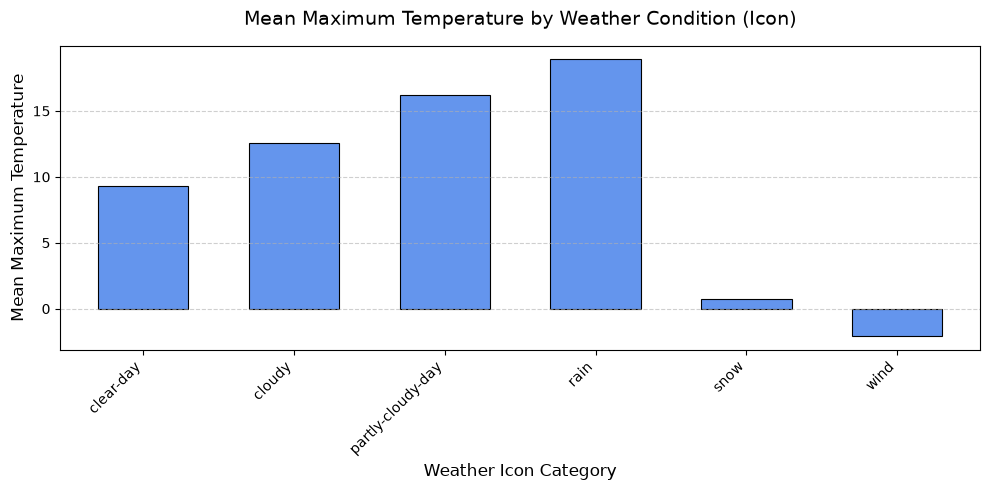

In [95]:
# Your Solution
'''Compute mean and chart data'''
df_weather = pd.read_csv('02215_weather.csv')
df_weather['datetime'] = pd.to_datetime(df_weather['datetime'])
df_weather.set_index('datetime', inplace=True)

df_weather['icon'] = df_weather['icon'].astype('category')
grouped_weather = df_weather.groupby('icon', observed=False)

mean_tempmax = grouped_weather['tempmax'].mean()

plt.figure(figsize=(10, 5))
mean_tempmax.plot(
    kind='bar',
    color='cornflowerblue',
    edgecolor='black',
    linewidth=0.8,
    width=0.6,
)

''' Add title, labels, and grid formatting '''
plt.title(
    'Mean Maximum Temperature by Weather Condition (Icon)', fontsize=14, pad=15
)
plt.xlabel('Weather Icon Category', fontsize=12)
plt.ylabel('Mean Maximum Temperature', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()



**Problem 7**

**Concept:** *Grouping data, descriptive statistics*


**Task:**

Using the `02215_weather.csv` dataset:

1. Group the DataFrame by the `icon` column and store the result in a variable named `grouped_by_icon`.
2. Compute descriptive statistics for the `tempmax` column for each group and store the result in a variable named `grouped_tempmax_statistics`.
3. Compute descriptive statistics for the `precip` column for each group and store the result in a variable named `grouped_precipitation_statistics`.
4. Compute the **mean** of the `tempmax` column for each group and store the result in a variable named `grouped_tempmax_mean`.

Print all three results with clear labels:
* `"Tempmax grouped by conditions"`
* `"Precipitation grouped by conditions"`
* `"Mean of tempmax grouped by conditions"`


In [96]:
# Your Solution
'''Group DF data, compute descriptive statistics'''
df_weather = pd.read_csv('02215_weather.csv')
df_weather['datetime'] = pd.to_datetime(df_weather['datetime'])
df_weather.set_index('datetime', inplace=True)

df_weather['icon'] = df_weather['icon'].astype('category')
grouped_by_icon = df_weather.groupby('icon', observed=False)

grouped_tempmax_statistics = grouped_by_icon['tempmax'].describe()

grouped_precipitation_statistics = grouped_by_icon['precip'].describe()

grouped_tempmax_mean = grouped_by_icon['tempmax'].mean()

print('Tempmax grouped by conditions')
print(grouped_tempmax_statistics)
print('\n' + '=' * 60 + '\n')

print('Precipitation grouped by conditions')
print(grouped_precipitation_statistics)
print('\n' + '=' * 60 + '\n')

print('Mean of tempmax grouped by conditions')
print(grouped_tempmax_mean)



Tempmax grouped by conditions
                   count       mean        std  min    25%    50%     75%  \
icon                                                                        
clear-day           12.0   9.316667   8.230965 -6.4   4.15  12.10  15.225   
cloudy               8.0  12.575000  10.423565 -1.3   4.95  13.05  21.350   
partly-cloudy-day  176.0  16.246023  10.533554 -8.1   7.20  15.65  25.000   
rain               150.0  18.904000   8.498037  0.8  12.60  19.90  24.600   
snow                18.0   0.750000   1.805628 -2.7  -0.65   1.25   1.775   
wind                 1.0  -2.100000        NaN -2.1  -2.10  -2.10  -2.100   

                    max  
icon                     
clear-day          20.8  
cloudy             24.4  
partly-cloudy-day  36.4  
rain               36.4  
snow                4.0  
wind               -2.1  


Precipitation grouped by conditions
                   count      mean        std    min      25%     50%  \
icon                              

/tmp/ipykernel_2206/3156019324.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_weather['datetime'] = pd.to_datetime(df_weather['datetime'])
/tmp/ipykernel_2206/3156019324.py:5: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_weather.set_index('datetime', inplace=True)


QUERYING

The following data frame will be used in several questions.


In [97]:
# starter code
df_voter_data = pd.read_csv("https://raw.githubusercontent.com/bu-cds-dx602/homework/main/week-11/newton_voters.csv", low_memory=False)
df_voter_data.index = df_voter_data["Voter ID Number"]
df_voter_data['Date of Birth'] = pd.to_datetime(df_voter_data['Date of Birth'])


**Problem 8**

**Concept:** *Querying `DataFrame`s and graphing*


**Task:**

Using the `df_voter_data` DataFrame:
1. Determine the **total number of voters** and print the result.
2. Compute the count of voters in each **Party Affiliation** category.
3. Create a **pie chart** showing the distribution of voters by party affiliation.

Your plot should include:
* labels for each category
* a title that includes the total number of voters


Total number of voters: 58,769

Voter count by Party Affiliation:
Party Affiliation
U     32416
D     23108
R      2854
CC      110
L       103
J        28
T        27
O        22
A        20
Q        19
S        14
G        10
X         8
AA        7
Z         5
FF        4
GG        3
V         2
K         2
HH        1
P         1
E         1
H         1
Y         1
W         1
EE        1
Name: count, dtype: int64


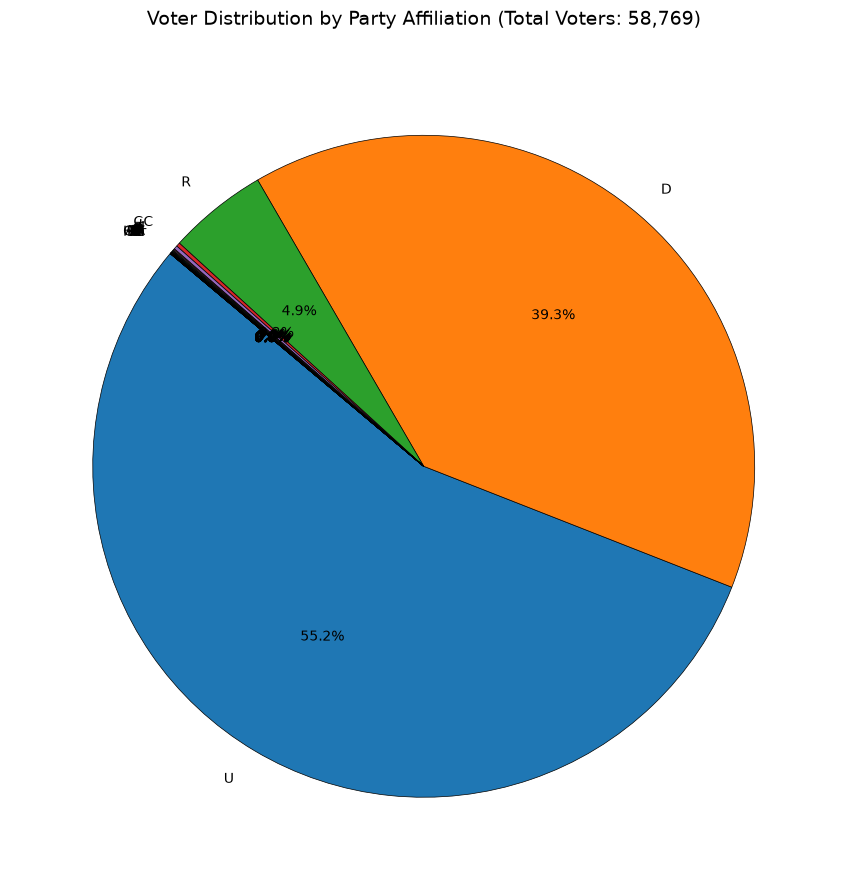

In [98]:
# Your Solution
'''print voter data, compute count of voter data'''
df_voter_data = pd.read_csv(
    'https://raw.githubusercontent.com/bu-cds-dx602/homework/main/week-11/newton_voters.csv',
    low_memory=False,
)
df_voter_data.index = df_voter_data['Voter ID Number']
df_voter_data['Date of Birth'] = pd.to_datetime(df_voter_data['Date of Birth'])

total_voters = len(df_voter_data)
print(f'Total number of voters: {total_voters:,}\n')

party_counts = df_voter_data['Party Affiliation'].fillna('Unknown').value_counts()
print('Voter count by Party Affiliation:')
print(party_counts)

plt.figure(figsize=(9, 9))
plt.pie(
    party_counts,
    labels=party_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    wedgeprops={'edgecolor': 'black', 'linewidth': 0.5},
)

plt.title(
    f'Voter Distribution by Party Affiliation (Total Voters: {total_voters:,})',
    fontsize=14,
    pad=20,
)

plt.tight_layout()



**Problem 9**

**Concept:** *Querying `DataFrame`s and graphing*


**Task:**

Using the `df_voter_data` DataFrame:
1. Create a new DataFrame named `df_older_voters` that includes only voters born **before January 1, 1950**.
    * Use the `.query()` method
    * Note: use backticks for column names containing spaces
2. Print the total number of voters in this filtered dataset.
3. Compute the count of voters in each **Party Affiliation** category for this subset.
4. Create a **pie chart** showing the distribution of party affiliations among these older voters.

Your plot should include:
* labels for each category
* a title that includes the number of older voters


Total number of voters born before January 1, 1950: 9,073

Older voter count by Party Affiliation:
Party Affiliation
U     4381
D     4141
R      520
CC      14
L        5
T        4
O        2
Z        1
Q        1
A        1
AA       1
J        1
K        1
Name: count, dtype: int64


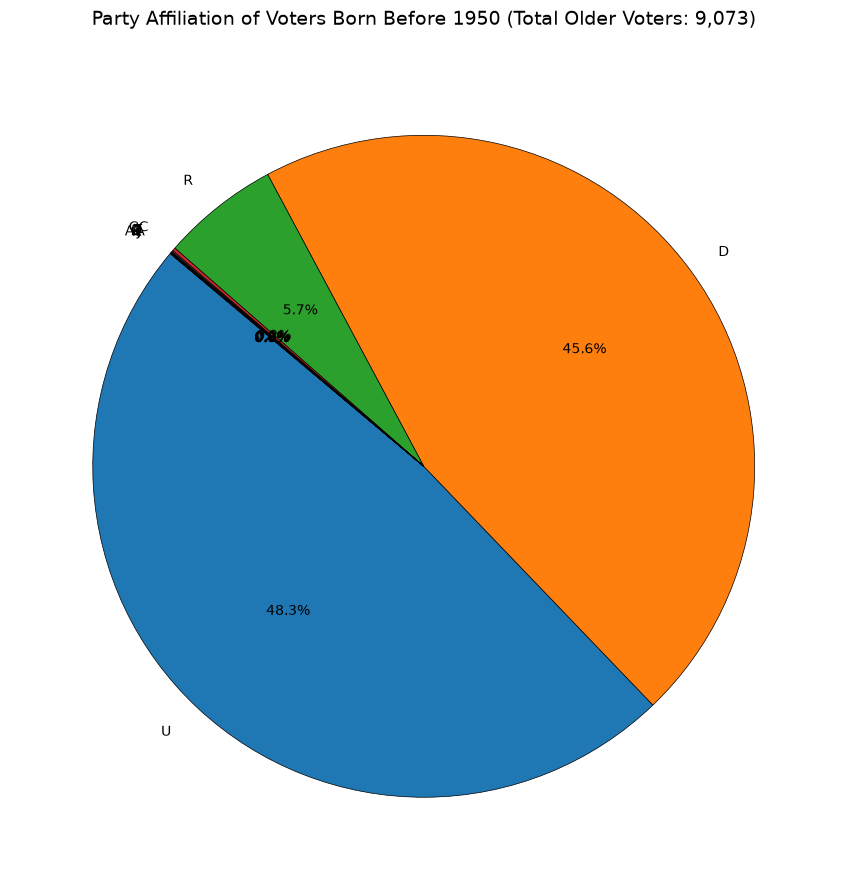

In [99]:
# Your Solution
'''Create new DFs and compute voter data'''
df_voter_data = pd.read_csv(
    'https://raw.githubusercontent.com/bu-cds-dx602/homework/main/week-11/newton_voters.csv',
    low_memory=False,
)
df_voter_data.index = df_voter_data['Voter ID Number']
df_voter_data['Date of Birth'] = pd.to_datetime(df_voter_data['Date of Birth'])

df_older_voters = df_voter_data.query("`Date of Birth` < '1950-01-01'")

total_older_voters = len(df_older_voters)
print(
    'Total number of voters born before January 1, 1950:'
    f' {total_older_voters:,}\n'
)

older_party_counts = (
    df_older_voters['Party Affiliation'].fillna('Unknown').value_counts()
)
print('Older voter count by Party Affiliation:')
print(older_party_counts)

plt.figure(figsize=(9, 9))
plt.pie(
    older_party_counts,
    labels=older_party_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    wedgeprops={'edgecolor': 'black', 'linewidth': 0.5},
)

plt.title(
    'Party Affiliation of Voters Born Before 1950 (Total Older Voters:'
    f' {total_older_voters:,})',
    fontsize=14,
    pad=20,
)

plt.tight_layout()



**Problem 10**

**Concept:** *Querying `DataFrame`s and graphing*


**Task:**

Using the `df_voter_data` DataFrame:
1. Create a new DataFrame named `df_younger_voters` that includes only voters born **after January 1, 2000**.
    * Use the `.query()` method
    * Note: use backticks for column names containing spaces
2. Print the total number of voters in this filtered dataset.
3. Compute the count of voters in each **Party Affiliation** category for this subset.
4. Create a **pie chart** showing the distribution of party affiliations among these Younger voters.

Your plot should include:
* labels for each category
* a title that includes the number of younger voters


Total number of voters born after January 1, 2000: 5,099

Younger voter count by Party Affiliation:
Party Affiliation
U     3533
D     1406
R      126
L       17
S        4
CC       3
J        2
A        2
HH       1
P        1
G        1
GG       1
AA       1
X        1
Name: count, dtype: int64


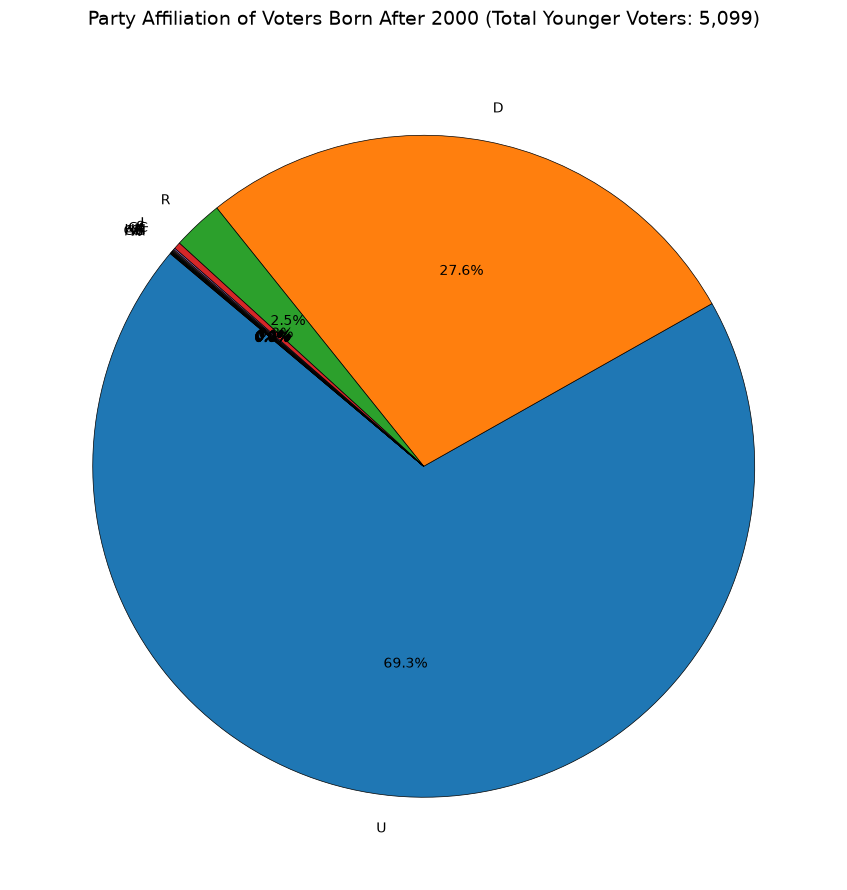

In [100]:
# Your Solution
'''Create new DFs compute voter data'''
f_voter_data = pd.read_csv(
    'https://raw.githubusercontent.com/bu-cds-dx602/homework/main/week-11/newton_voters.csv',
    low_memory=False,
)
df_voter_data.index = df_voter_data['Voter ID Number']
df_voter_data['Date of Birth'] = pd.to_datetime(df_voter_data['Date of Birth'])

df_younger_voters = df_voter_data.query("`Date of Birth` > '2000-01-01'")

total_younger_voters = len(df_younger_voters)
print(
    'Total number of voters born after January 1, 2000:'
    f' {total_younger_voters:,}\n'
)

younger_party_counts = (
    df_younger_voters['Party Affiliation'].fillna('Unknown').value_counts()
)
print('Younger voter count by Party Affiliation:')
print(younger_party_counts)

plt.figure(figsize=(9, 9))
plt.pie(
    younger_party_counts,
    labels=younger_party_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    wedgeprops={'edgecolor': 'black', 'linewidth': 0.5},
)

plt.title(
    'Party Affiliation of Voters Born After 2000 (Total Younger Voters:'
    f' {total_younger_voters:,})',
    fontsize=14,
    pad=20,
)

plt.tight_layout()



**Problem 11**

**Concept:** *Querying `DataFrame`s and graphing*



**Task:**

Using the `df_voter_data` DataFrame:
1. Identify all columns related to elections:
    * Select columns whose names contain the letter `"v"` but do **not** contain `"score"`
    * Store the result in a variable named `election_columns`

2. Compute the **voting participation percentage** for each election among all voters:
    * Store the result in a variable named `d1`
    * **Hint:** To calculate participation
        * Use `.sum()` on a column to count how many voters participated
        * Divide by the total number of voters using `len(df)`
        * Multiply by 100 to convert to a percentage

3. Create a filtered DataFrame named `df_high_voter_score`:
    * Include only voters with `voter_score >= 4`
    * Print the number of voters in this group

4. Compute the **voting participation percentage** for this group:
    * Store the result in a variable named `d2`

5. Create a filtered DataFrame named `df_unenrolled`:
    * Include only voters with `"Party Affiliation" == "U "`
    * Print the number of voters in this group

6. Compute the voting participation percentage for this group:
    * Store the result in a variable named `d3`

7. Combine the results into a new DataFrame named `d`:
    * Index should be the election columns
    * Columns should be:
        * `"all voters"`
        * `"high-propensity voters"`
        * `"unenrolled voters"`

8. Create a **bar chart** from this combined DataFrame.

Your plot should include:
* a title
* a key

Number of high-propensity voters (voter_score >= 4): 15,245
Number of unenrolled voters ("U "): 32,416

Combined Percentages (%):
            all voters  high-propensity voters  unenrolled voters
v20state         71.03                   96.65              65.68
v21town          33.53                   91.53              27.72
v21primary       21.95                   66.70              11.25
v22general       61.48                   99.13              55.41
v23town          33.92                   87.04              30.49


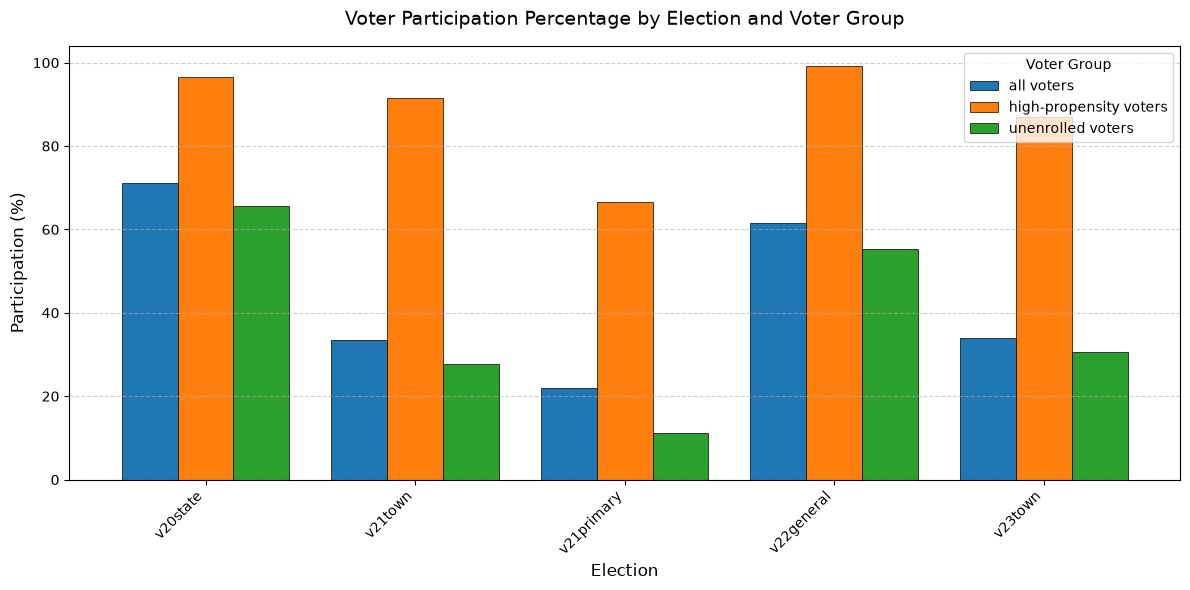

In [101]:
# Your Solution
'''compute voter statistics'''
df_voter_data = pd.read_csv(
    'https://raw.githubusercontent.com/bu-cds-dx602/homework/main/week-11/newton_voters.csv',
    low_memory=False,
)
df_voter_data.index = df_voter_data['Voter ID Number']


df_voter_data['Date of Birth'] = pd.to_datetime(df_voter_data['Date of Birth'])


election_columns = [
    col
    for col in df_voter_data.columns
    if 'v' in col and 'score' not in col.lower()
]

d1 = (df_voter_data[election_columns].sum() / len(df_voter_data[election_columns])) * 100

df_high_voter_score = df_voter_data[df_voter_data['voter_score'] >= 4]
print(f'Number of high-propensity voters (voter_score >= 4): {len(df_high_voter_score):,}')

d2 = (
    df_high_voter_score[election_columns].sum() / len(df_high_voter_score)
) * 100

df_unenrolled = df_voter_data[df_voter_data['Party Affiliation'] == 'U ']
print(f'Number of unenrolled voters ("U "): {len(df_unenrolled):,}\n')

d3 = (df_unenrolled[election_columns].sum() / len(df_unenrolled)) * 100

d = pd.DataFrame(
    {
        'all voters': d1,
        'high-propensity voters': d2,
        'unenrolled voters': d3,
    },
    index=election_columns,
)

print('Combined Percentages (%):')
print(d.round(2))

ax = d.plot(kind='bar', figsize=(12, 6), width=0.8, edgecolor='black', linewidth=0.5)

plt.title('Voter Participation Percentage by Election and Voter Group', fontsize=14, pad=15)
plt.xlabel('Election', fontsize=12)
plt.ylabel('Participation (%)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Voter Group', loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()



**Problem 12**

**Concept:** *Joining `DataFrame`s*


**Task:**

You are given two DataFrames:
* `submissions`, which contains student IDs and their homework submission IDs
* `grades`, which contains homework grades indexed by submission ID

Using these DataFrames:
1. Inspect both DataFrames by printing them.
2. Join the `submissions` DataFrame with the `grades` DataFrame:
    * Match the `hw1_submission` column in `submissions` with the index of `grades`
    * Store the result in a variable named `result`
3. Update the index of the resulting DataFrame:
    * Set the index to the `student_id` column
4. Create a new DataFrame named `result_df`:
    * Remove the `student_id` column
5. Print the final DataFrame


Starter code:

In [102]:
# STARTER CODE:
submissions = pd.DataFrame(data={"student_id": ["U100", "U101", "U102", "U103", "U104"],
                        "hw1_submission": ["c1325", "b231", "a512", "e9999", "d8234"]})

grades = pd.DataFrame(index=["a512", "b231", "c1325", "d8234", "e9999"],
                        data={"hw1_grade": [0.99, 0.50, 0.62, 0.78, 1.00]} )



In [103]:
# Your Solution
'''Join Dfs, create new DF'''

print('Submissions DataFrame')
print(submissions)
print('\nGrades DataFrame')
print(grades)

result = submissions.join(grades, on='hw1_submission')

result.index = result['student_id']

result_df = result.drop(columns=['student_id'])

print('\n--- Final DataFrame (result_df) ---')
print(result_df)



Submissions DataFrame
  student_id hw1_submission
0       U100          c1325
1       U101           b231
2       U102           a512
3       U103          e9999
4       U104          d8234

Grades DataFrame
       hw1_grade
a512        0.99
b231        0.50
c1325       0.62
d8234       0.78
e9999       1.00

--- Final DataFrame (result_df) ---
           hw1_submission  hw1_grade
student_id                          
U100                c1325       0.62
U101                 b231       0.50
U102                 a512       0.99
U103                e9999       1.00
U104                d8234       0.78


**Problem 13**

**Concept:** *Joining `DataFrame`s*



**Task:**

You are given two datasets:
* `design_materials.tsv`, which contains materials and the quantity required per bed
* `material_costs.tsv`, which contains the cost per unit for each material

Using these datasets:
1. Load both datasets from the provided `.tsv` files using the correct separator.
2. Merge the two DataFrames:
    * Join on the `material` column
    * Store the result in a variable named `df_costs`
3. Create a new column named `cost`:
    * Compute it as:

      **quantity_per_bed × unit_cost**
4. Print the resulting DataFrame

In [104]:
# Your Solution
'''Merge DFs'''
df_materials = pd.read_csv('design_materials.tsv', sep='\t')
df_unit_costs = pd.read_csv('material_costs.tsv', sep='\t')

df_costs = pd.merge(df_materials, df_unit_costs, on='material')

df_costs['cost'] = df_costs['quantity_per_bed'] * df_costs['unit_cost']

print(df_costs)



          design                    material  quantity_per_bed  unit_cost  \
0  4' x 4' x 18"                2" x 6" x 4'                20       5.92   
1  4' x 4' x 18"  8" x 8" x 16" Cinder Block                12       3.53   
2  4' x 8' x 18"                2" x 6" x 4'                 6       5.92   
3  4' x 8' x 18"                2" x 6" x 8'                14       7.62   
4  4' x 8' x 18"  8" x 8" x 16" Cinder Block                24       3.53   
5  4' x 4' x 12"                2" x 6" x 4'                16       5.92   
6  4' x 4' x 12"  8" x 8" x 16" Cinder Block                12       3.53   
7  4' x 8' x 12"                2" x 6" x 4'                 2       5.92   
8  4' x 8' x 12"                2" x 6" x 8'                12       7.62   
9  4' x 8' x 12"  8" x 8" x 16" Cinder Block                24       3.53   

     cost  
0  118.40  
1   42.36  
2   35.52  
3  106.68  
4   84.72  
5   94.72  
6   42.36  
7   11.84  
8   91.44  
9   84.72  


**Problem 14**

**Concept:** *joining `DataFrame`s*


**Task:**

You are given three stock datasets:
* BAC
* GM
* SBUX

Using these datasets:
1. Load each dataset into separate DataFrames:
    * `df_bac`, `df_gm`, and `df_sbux`
2. Convert the `date` column in each DataFrame to pandas datetime format and set it as the index.
3. Create a new DataFrame named `df_stock_prices`:
    * Use the index from `df_bac`
    * Add the following columns:
        * `"bac"` from `df_bac["close"]`
        * `"gm"` from `df_gm["close"]`
        * `"sbux"` from `df_sbux["close"]`
4. Create a **line plot** showing the stock prices over time.

Your plot should include:
* all three stocks on the same chart
* a title

/tmp/ipykernel_2206/345138229.py:9: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index('date', inplace=True)
/tmp/ipykernel_2206/345138229.py:9: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index('date', inplace=True)
/tmp/ipykernel_2206/345138229.py:9: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index('date', inplace=True)


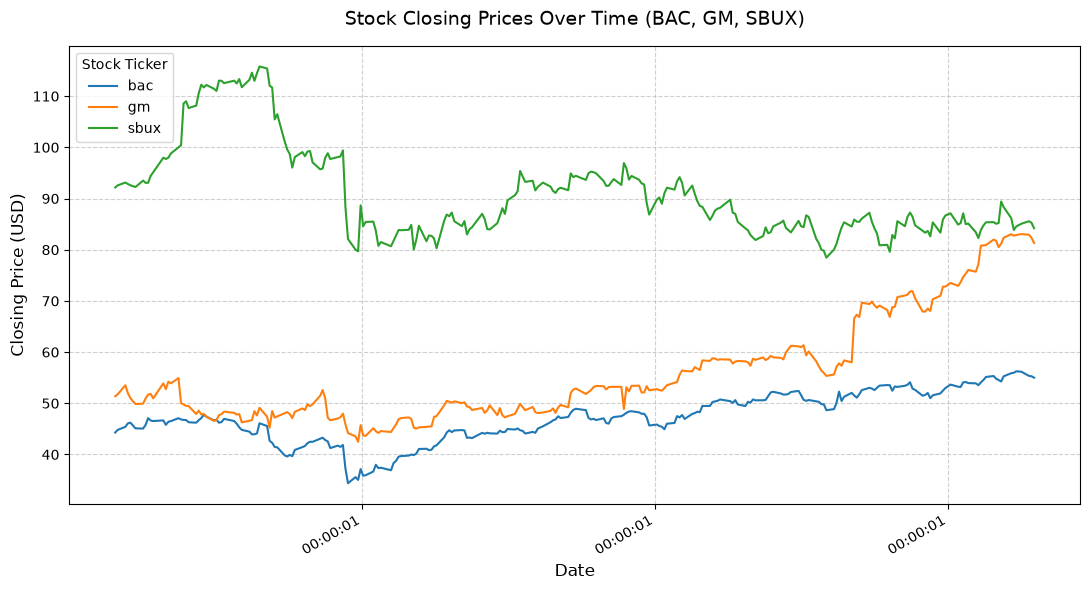

In [105]:
# Your Solution
'''Merge data sets'''
df_bac = pd.read_csv('BAC.csv')
df_gm = pd.read_csv('GM.csv')
df_sbux = pd.read_csv('SBUX.csv')

for df in [df_bac, df_gm, df_sbux]:
  df['date'] = pd.to_datetime(df['date'])
  df.set_index('date', inplace=True)

df_stock_prices = pd.DataFrame(index=df_bac.index)
df_stock_prices['bac'] = df_bac['close']
df_stock_prices['gm'] = df_gm['close']
df_stock_prices['sbux'] = df_sbux['close']

df_stock_prices.plot(figsize=(11, 6), linewidth=1.5)

plt.title('Stock Closing Prices Over Time (BAC, GM, SBUX)', fontsize=14, pad=15)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Closing Price (USD)', fontsize=12)
plt.legend(title='Stock Ticker', loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()



**Problem 15**

**Concept:** *joining `DataFrame`s*


**Task:**

Using the `df_stock_prices` DataFrame from **Problem 14**:
1. Compute the **relative prices** of each stock:
    * Divide all values by the first row of the DataFrame
    * Store the result in a variable named `df_stock_prices_relative`
2. Create a **line plot** of the relative prices.

Your plot should include:
* all three stocks on the same chart
* a title

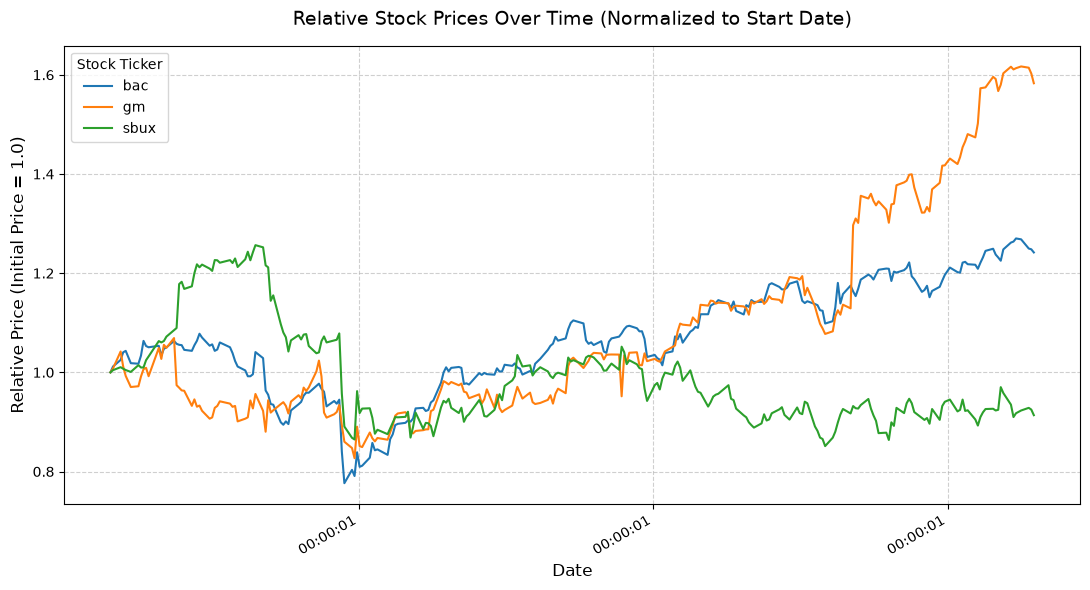

In [106]:
# Your Solution
'''Use previous code and join DFs'''
df_stock_prices_relative = df_stock_prices / df_stock_prices.iloc[0]

df_stock_prices_relative.plot(figsize=(11, 6), linewidth=1.5)

plt.title(
    'Relative Stock Prices Over Time (Normalized to Start Date)',
    fontsize=14,
    pad=15,
)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Relative Price (Initial Price = 1.0)', fontsize=12)
plt.legend(title='Stock Ticker', loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()

